In [1]:
import os
import json
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_curve, roc_auc_score


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# RAKSHAVOICE FEATURE PATH
# ============================================================

F = "/kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features"

print("\nFeature directory:")
print(F)


# ============================================================
# CHECK REQUIRED FILES
# ============================================================

required_files = [
    "train_X.npy",
    "train_y.npy",
    "dev_X.npy",
    "dev_y.npy",
    "eval_random_20000_X.npy",
    "eval_random_20000_y.npy"
]

for file in required_files:
    path = os.path.join(F, file)
    print(
        f"{file:25s} -> "
        f"{'FOUND' if os.path.exists(path) else 'MISSING'}"
    )

Device: cuda
GPU: Tesla T4

Feature directory:
/kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features
train_X.npy               -> FOUND
train_y.npy               -> FOUND
dev_X.npy                 -> FOUND
dev_y.npy                 -> FOUND
eval_random_20000_X.npy   -> FOUND
eval_random_20000_y.npy   -> FOUND


In [2]:
import os

# Read-only input dataset
F = "/kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features"

# Writable output directory
OUTPUT_DIR = "/kaggle/working"

# Model checkpoint
CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR,
    "spoof_head.pt"
)

# Other Step 4 outputs
CURVE_PATH = os.path.join(
    OUTPUT_DIR,
    "training_curve.png"
)

TRAIN_LOG_PATH = os.path.join(
    OUTPUT_DIR,
    "train_log.json"
)

LAYER_WEIGHTS_PATH = os.path.join(
    OUTPUT_DIR,
    "layer_weights.npy"
)

print("Input:", F)
print("Output:", OUTPUT_DIR)

print("\nCheckpoint will be saved to:")
print(CHECKPOINT_PATH)

Input: /kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features
Output: /kaggle/working

Checkpoint will be saved to:
/kaggle/working/spoof_head.pt


In [3]:
def make_loader(name, shuffle):

    X_path = os.path.join(F, f"{name}_X.npy")
    y_path = os.path.join(F, f"{name}_y.npy")

    X = torch.tensor(
        np.load(X_path),
        dtype=torch.float32
    )

    y = torch.tensor(
        np.load(y_path),
        dtype=torch.float32
    )

    dataset = TensorDataset(X, y)

    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    return loader, y


tr, ytr = make_loader("train", True)
dv, ydv = make_loader("dev", False)


print("Training samples:", len(ytr))
print("Validation samples:", len(ydv))

print("\nTraining X shape:")
print(tr.dataset.tensors[0].shape)

print("\nValidation X shape:")
print(dv.dataset.tensors[0].shape)

print("\nTraining label distribution:")
print(torch.unique(ytr, return_counts=True))

print("\nValidation label distribution:")
print(torch.unique(ydv, return_counts=True))

print("\nTraining spoof fraction:")
print(ytr.mean().item())

Training samples: 25380
Validation samples: 24844

Training X shape:
torch.Size([25380, 13, 768])

Validation X shape:
torch.Size([24844, 13, 768])

Training label distribution:
(tensor([0., 1.]), tensor([ 2580, 22800]))

Validation label distribution:
(tensor([0., 1.]), tensor([ 2548, 22296]))

Training spoof fraction:
0.8983451724052429


In [4]:
num_bonafide = (ytr == 0).sum().item()
num_spoof = (ytr == 1).sum().item()

pos_weight_value = num_bonafide / num_spoof

pos_weight = torch.tensor(
    pos_weight_value,
    dtype=torch.float32,
    device=device
)

print("Bonafide samples:", num_bonafide)
print("Spoof samples:", num_spoof)
print("pos_weight:", pos_weight.item())

Bonafide samples: 2580
Spoof samples: 22800
pos_weight: 0.11315789818763733


In [5]:
class SpoofHead(nn.Module):

    def __init__(self, L=13, D=768):

        super().__init__()

        # ----------------------------------------------------
        # Learnable importance for each Wav2Vec2 layer
        # ----------------------------------------------------

        self.w = nn.Parameter(
            torch.zeros(L)
        )


        # ----------------------------------------------------
        # Custom classifier
        # ----------------------------------------------------

        self.net = nn.Sequential(

            nn.LayerNorm(D),

            nn.Linear(D, 256),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(256, 1)
        )


    def forward(self, x):

        # x shape:
        # (batch, 13, 768)

        # Convert layer weights to probabilities
        a = torch.softmax(
            self.w,
            dim=0
        )

        # (13,) -> (1, 13, 1)
        a = a[None, :, None]

        # Weighted combination of 13 Wav2Vec2 layers
        x = (x * a).sum(dim=1)

        # x shape now:
        # (batch, 768)

        # Classifier
        output = self.net(x)

        # (batch, 1) -> (batch,)
        return output.squeeze(-1)

In [6]:
head = SpoofHead().to(device)

print(head)

total_params = sum(
    p.numel()
    for p in head.parameters()
)

trainable_params = sum(
    p.numel()
    for p in head.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", total_params)
print("Trainable parameters:", trainable_params)

SpoofHead(
  (net): Sequential(
    (0): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=768, out_features=256, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)

Total parameters: 198670
Trainable parameters: 198670


In [7]:
loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    head.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Loss:", loss_fn)
print("Optimizer:", optimizer)

Loss: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [8]:
def eer(y_true, scores):

    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores,
        pos_label=1
    )

    fnr = 1 - tpr

    index = np.nanargmin(
        np.abs(fnr - fpr)
    )

    eer_value = (
        fpr[index] + fnr[index]
    ) / 2

    return float(eer_value)

In [9]:
def evaluate(model, loader):

    model.eval()

    scores = []

    with torch.no_grad():

        for x, _ in loader:

            x = x.to(
                device,
                non_blocking=True
            )

            logits = model(x)

            probabilities = torch.sigmoid(
                logits
            )

            scores.extend(
                probabilities.cpu().numpy()
            )

    return np.asarray(scores)

In [10]:
import os

# INPUT: read-only, contains the .npy files
F = "/kaggle/input/rakshavoice-features"

# OUTPUT: writable
OUTPUT_DIR = "/kaggle/working"

CHECKPOINT_PATH = "/kaggle/working/spoof_head.pt"

CURVE_PATH = "/kaggle/working/training_curve.png"

TRAIN_LOG_PATH = "/kaggle/working/train_log.json"

LAYER_WEIGHTS_PATH = "/kaggle/working/layer_weights.npy"


print("F =", F)
print("CHECKPOINT_PATH =", CHECKPOINT_PATH)

print("\nCheckpoint directory writable:",
      os.access("/kaggle/working", os.W_OK))

print("\nCheckpoint currently exists:",
      os.path.exists(CHECKPOINT_PATH))

F = /kaggle/input/rakshavoice-features
CHECKPOINT_PATH = /kaggle/working/spoof_head.pt

Checkpoint directory writable: True

Checkpoint currently exists: False


In [11]:
head = SpoofHead().to(device)

optimizer = torch.optim.Adam(
    head.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Fresh model created.")

Fresh model created.


In [13]:
NUM_EPOCHS = 30
PATIENCE = 5

best = float("inf")
bad = 0
best_epoch = -1

log = {
    "epoch": [],
    "train_loss": [],
    "dev_eer": []
}

CHECKPOINT_PATH = "/kaggle/working/spoof_head.pt"


for ep in range(1, NUM_EPOCHS + 1):

    # -----------------------------
    # TRAIN
    # -----------------------------

    head.train()

    total_loss = 0.0
    total_samples = 0

    for x, y in tr:

        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = head(x)

        loss = loss_fn(logits, y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * len(x)
        total_samples += len(x)

    train_loss = total_loss / total_samples


    # -----------------------------
    # VALIDATION
    # -----------------------------

    dev_scores = evaluate(head, dv)

    dev_eer = eer(
        ydv.numpy(),
        dev_scores
    )


    # -----------------------------
    # LOG
    # -----------------------------

    log["epoch"].append(ep)
    log["train_loss"].append(float(train_loss))
    log["dev_eer"].append(float(dev_eer))


    # -----------------------------
    # BEST CHECKPOINT
    # -----------------------------

    if dev_eer < best:

        best = dev_eer
        bad = 0
        best_epoch = ep

        torch.save(
            head.state_dict(),
            "/kaggle/working/spoof_head.pt"
        )

        marker = " <-- BEST"

    else:

        bad += 1
        marker = ""


    print(
        f"Epoch {ep:02d}/{NUM_EPOCHS} | "
        f"Loss {train_loss:.4f} | "
        f"Dev EER {dev_eer * 100:.2f}%"
        f"{marker}"
    )


    # -----------------------------
    # EARLY STOPPING
    # -----------------------------

    if bad >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {ep}"
        )

        print(
            f"Best epoch: {best_epoch}"
        )

        print(
            f"Best Dev EER: {best * 100:.2f}%"
        )

        break


print("\n==============================")
print("TRAINING FINISHED")
print("==============================")
print("Best epoch:", best_epoch)
print(f"Best Dev EER: {best * 100:.2f}%")
print("Saved model: /kaggle/working/spoof_head.pt")

Epoch 01/30 | Loss 0.0031 | Dev EER 0.67% <-- BEST
Epoch 02/30 | Loss 0.0027 | Dev EER 0.55% <-- BEST
Epoch 03/30 | Loss 0.0026 | Dev EER 0.61%
Epoch 04/30 | Loss 0.0036 | Dev EER 0.67%
Epoch 05/30 | Loss 0.0028 | Dev EER 0.59%
Epoch 06/30 | Loss 0.0025 | Dev EER 0.90%
Epoch 07/30 | Loss 0.0022 | Dev EER 0.74%

Early stopping at epoch 7
Best epoch: 2
Best Dev EER: 0.55%

TRAINING FINISHED
Best epoch: 2
Best Dev EER: 0.55%
Saved model: /kaggle/working/spoof_head.pt


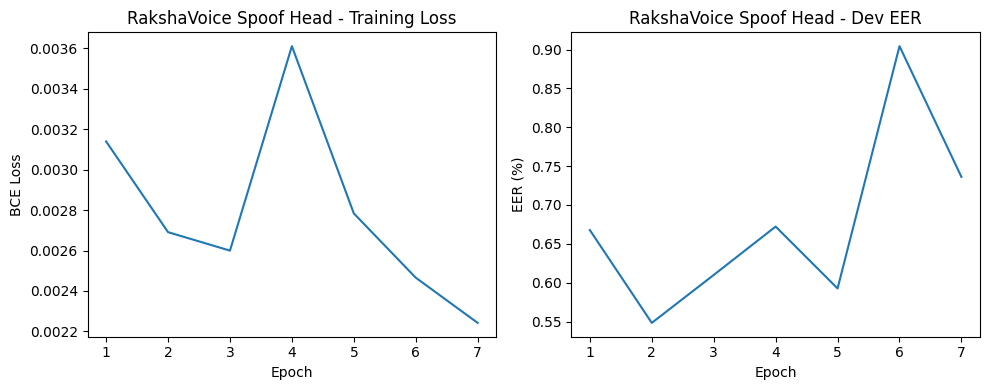

Saved: /kaggle/working/training_curve.png


In [14]:
import matplotlib.pyplot as plt


fig, ax = plt.subplots(
    1,
    2,
    figsize=(10, 4)
)


# Train loss
ax[0].plot(
    log["epoch"],
    log["train_loss"]
)

ax[0].set_title(
    "RakshaVoice Spoof Head - Training Loss"
)

ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("BCE Loss")


# Dev EER
ax[1].plot(
    log["epoch"],
    [e * 100 for e in log["dev_eer"]]
)

ax[1].set_title(
    "RakshaVoice Spoof Head - Dev EER"
)

ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("EER (%)")


plt.tight_layout()


CURVE_PATH = os.path.join(
    '/kaggle/working',
    "training_curve.png"
)

plt.savefig(
    CURVE_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Saved:", CURVE_PATH)

In [15]:
head.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

head.eval()

print("Best checkpoint loaded successfully.")

Best checkpoint loaded successfully.


In [16]:
with torch.no_grad():

    lw = torch.softmax(
        head.w,
        dim=0
    ).cpu().numpy()


print("Learned Wav2Vec2 layer weights:")
print(
    np.round(lw, 4)
)

print("\nSum:")
print(lw.sum())

Learned Wav2Vec2 layer weights:
[0.0638 0.0565 0.0613 0.1044 0.1569 0.134  0.0782 0.0715 0.059  0.0568
 0.043  0.0505 0.064 ]

Sum:
1.0


In [17]:
for i, weight in enumerate(lw, start=1):

    print(
        f"Wav2Vec2 Layer {i:02d}: "
        f"{weight:.4f} "
        f"({weight * 100:.2f}%)"
    )

Wav2Vec2 Layer 01: 0.0638 (6.38%)
Wav2Vec2 Layer 02: 0.0565 (5.65%)
Wav2Vec2 Layer 03: 0.0613 (6.13%)
Wav2Vec2 Layer 04: 0.1044 (10.44%)
Wav2Vec2 Layer 05: 0.1569 (15.69%)
Wav2Vec2 Layer 06: 0.1340 (13.40%)
Wav2Vec2 Layer 07: 0.0782 (7.82%)
Wav2Vec2 Layer 08: 0.0715 (7.15%)
Wav2Vec2 Layer 09: 0.0590 (5.90%)
Wav2Vec2 Layer 10: 0.0568 (5.68%)
Wav2Vec2 Layer 11: 0.0430 (4.30%)
Wav2Vec2 Layer 12: 0.0505 (5.05%)
Wav2Vec2 Layer 13: 0.0640 (6.40%)


In [18]:
LAYER_WEIGHTS_PATH = os.path.join(
    '/kaggle/working',
    "layer_weights.npy"
)

np.save(
    LAYER_WEIGHTS_PATH,
    lw
)

print(
    "Saved:",
    LAYER_WEIGHTS_PATH
)

Saved: /kaggle/working/layer_weights.npy


In [19]:
TRAIN_LOG_PATH = os.path.join(
    '/kaggle/working',
    "train_log.json"
)


params = sum(
    p.numel()
    for p in head.parameters()
)


training_record = {
    "epoch": log["epoch"],
    "train_loss": log["train_loss"],
    "dev_eer": log["dev_eer"],

    "best_epoch": int(best_epoch),

    "best_dev_eer": float(best),

    "best_dev_eer_percent": float(best * 100),

    "learning_rate": 1e-3,

    "batch_size": 128,

    "dropout": 0.3,

    "weight_decay": 1e-4,

    "max_epochs": 30,

    "early_stopping_patience": 5,

    "input_shape": [13, 768],

    "hidden_dimension": 256,

    "optimizer": "Adam",

    "loss": "BCEWithLogitsLoss",

    "pos_weight": float(
        pos_weight.item()
    ),

    "train_samples": int(
        len(ytr)
    ),

    "dev_samples": int(
        len(ydv)
    ),

    "bonafide_train": int(
        num_bonafide
    ),

    "spoof_train": int(
        num_spoof
    ),

    "parameters": int(params)
}


with open(
    TRAIN_LOG_PATH,
    "w"
) as f:

    json.dump(
        training_record,
        f,
        indent=4
    )


print(
    "Saved:",
    TRAIN_LOG_PATH
)

Saved: /kaggle/working/train_log.json


In [20]:
print("\n========================================")
print("RAKSHAVOICE — STEP 4 FILE CHECK")
print("========================================")


step4_files = [
    "spoof_head.pt",
    "training_curve.png",
    "train_log.json",
    "layer_weights.npy"
]


for filename in step4_files:

    path = os.path.join(
        '/kaggle/working',
        filename
    )

    if os.path.exists(path):

        size_mb = (
            os.path.getsize(path)
            / (1024 * 1024)
        )

        print(
            f"✓ {filename:25s} "
            f"{size_mb:.3f} MB"
        )

    else:

        print(
            f"✗ {filename:25s} MISSING"
        )


print("\nBest epoch:", best_epoch)

print(
    "Best Dev EER: "
    f"{best * 100:.2f}%"
)

print(
    "\nStep 4 checkpoint:"
)

print(CHECKPOINT_PATH)


RAKSHAVOICE — STEP 4 FILE CHECK
✓ spoof_head.pt             0.761 MB
✓ training_curve.png        0.077 MB
✓ train_log.json            0.001 MB
✓ layer_weights.npy         0.000 MB

Best epoch: 2
Best Dev EER: 0.55%

Step 4 checkpoint:
/kaggle/working/spoof_head.pt


In [21]:
import os
import json
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_curve, roc_auc_score


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# RAKSHAVOICE DIRECTORY
# ============================================================

F = "/kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features"


# ============================================================
# STEP 5 FILE PATHS
# ============================================================

EVAL_X = os.path.join(
    F,
    "eval_random_20000_X.npy"
)

EVAL_Y = os.path.join(
    F,
    "eval_random_20000_y.npy"
)

CHECKPOINT_PATH = os.path.join(
    '/kaggle/working',
    "spoof_head.pt"
)

RESULTS_PATH = os.path.join(
    '/kaggle/working',
    "results.json"
)

ROC_PATH = os.path.join(
    '/kaggle/working',
    "roc_curve.png"
)


print("Feature directory:", F)

print("\nRequired files:")

for path in [
    EVAL_X,
    EVAL_Y,
    CHECKPOINT_PATH
]:

    print(
        os.path.basename(path),
        "->",
        "FOUND" if os.path.exists(path)
        else "MISSING"
    )

Device: cuda
GPU: Tesla T4
Feature directory: /kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features

Required files:
eval_random_20000_X.npy -> FOUND
eval_random_20000_y.npy -> FOUND
spoof_head.pt -> FOUND


In [22]:
X_eval = np.load(EVAL_X)
y_eval = np.load(EVAL_Y)

print("Evaluation X shape:", X_eval.shape)
print("Evaluation y shape:", y_eval.shape)

print("\nEvaluation labels:")
print(
    np.unique(
        y_eval,
        return_counts=True
    )
)

print("\nEvaluation spoof fraction:")
print(y_eval.mean())

Evaluation X shape: (20000, 13, 768)
Evaluation y shape: (20000,)

Evaluation labels:
(array([0, 1]), array([ 2042, 17958]))

Evaluation spoof fraction:
0.8979


In [23]:
class SpoofHead(nn.Module):

    def __init__(self, L=13, D=768):

        super().__init__()

        # Learnable Wav2Vec2 layer weights
        self.w = nn.Parameter(
            torch.zeros(L)
        )

        # Custom classifier
        self.net = nn.Sequential(

            nn.LayerNorm(D),

            nn.Linear(D, 256),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(256, 1)
        )

    def forward(self, x):

        # Convert layer weights to normalized weights
        a = torch.softmax(
            self.w,
            dim=0
        )

        # (13,) -> (1, 13, 1)
        a = a[None, :, None]

        # Weighted combination
        x = (x * a).sum(dim=1)

        # Classifier
        return self.net(x).squeeze(-1)

In [24]:
head = SpoofHead().to(device)

head.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

head.eval()

print("Best spoof classifier loaded successfully.")
print("Checkpoint:", CHECKPOINT_PATH)

Best spoof classifier loaded successfully.
Checkpoint: /kaggle/working/spoof_head.pt


In [25]:
eval_dataset = TensorDataset(
    torch.tensor(
        X_eval,
        dtype=torch.float32
    ),
    torch.tensor(
        y_eval,
        dtype=torch.float32
    )
)

eval_loader = DataLoader(
    eval_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Evaluation samples:", len(eval_dataset))
print("Evaluation batches:", len(eval_loader))

Evaluation samples: 20000
Evaluation batches: 157


In [26]:
def evaluate(model, loader):

    model.eval()

    scores = []

    with torch.no_grad():

        for x, _ in loader:

            x = x.to(
                device,
                non_blocking=True
            )

            logits = model(x)

            probabilities = torch.sigmoid(
                logits
            )

            scores.extend(
                probabilities.cpu().numpy()
            )

    return np.asarray(scores)

In [28]:
s_ev = evaluate(
    head,
    eval_loader
)

print("Number of predictions:", len(s_ev))

print("\nFirst 10 spoof probabilities:")
print(s_ev[:10])

print("\nMinimum score:", s_ev.min())
print("Maximum score:", s_ev.max())
print("Mean score:", s_ev.mean())

Number of predictions: 20000

First 10 spoof probabilities:
[4.1135168e-05 9.9992025e-01 9.9979752e-01 3.6059262e-04 9.9992359e-01
 1.0000000e+00 9.9997878e-01 4.3521957e-03 9.9858814e-01 1.0000000e+00]

Minimum score: 8.92011e-12
Maximum score: 1.0
Mean score: 0.8368766


In [29]:
def full_metrics(y, s):

    fpr, tpr, thresholds = roc_curve(
        y,
        s,
        pos_label=1
    )

    fnr = 1 - tpr

    # Find the operating point where
    # FAR and FRR are closest
    i = np.nanargmin(
        np.abs(fnr - fpr)
    )

    eer_value = (
        fpr[i] + fnr[i]
    ) / 2

    return {
        "EER": float(eer_value),

        "AUC": float(
            roc_auc_score(
                y,
                s
            )
        ),

        "threshold": float(
            thresholds[i]
        ),

        "FAR": float(
            fpr[i]
        ),

        "FRR": float(
            fnr[i]
        )
    }

In [30]:
m_eval = full_metrics(
    y_eval,
    s_ev
)

print("\n====================================")
print("RAKSHAVOICE — FINAL EVAL RESULTS")
print("====================================")

for key, value in m_eval.items():

    if key == "threshold":
        print(
            f"{key:10s}: {value:.6f}"
        )

    else:
        print(
            f"{key:10s}: "
            f"{value:.6f} "
            f"({value * 100:.2f}%)"
        )


RAKSHAVOICE — FINAL EVAL RESULTS
EER       : 0.024438 (2.44%)
AUC       : 0.997248 (99.72%)
threshold : 0.115939
FAR       : 0.024486 (2.45%)
FRR       : 0.024390 (2.44%)


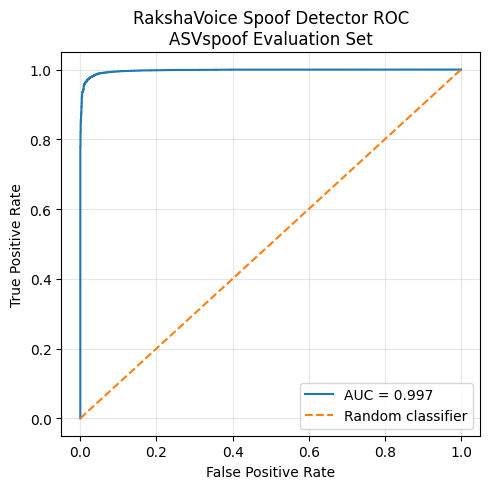

ROC curve saved to:
/kaggle/working/roc_curve.png


In [31]:
import matplotlib.pyplot as plt


fpr, tpr, thresholds = roc_curve(
    y_eval,
    s_ev,
    pos_label=1
)


plt.figure(
    figsize=(5, 5)
)

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {m_eval['AUC']:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "RakshaVoice Spoof Detector ROC\n"
    "ASVspoof Evaluation Set"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ROC_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved to:")
print(ROC_PATH)

In [32]:
TRAIN_LOG_PATH = os.path.join(
    '/kaggle/working',
    "train_log.json"
)

with open(
    TRAIN_LOG_PATH,
    "r"
) as f:

    train_record = json.load(f)


best_dev_eer = float(
    train_record["best_dev_eer"]
)

best_dev_epoch = int(
    train_record["best_epoch"]
)


print("Best Dev Epoch:", best_dev_epoch)

print(
    "Best Dev EER:",
    f"{best_dev_eer * 100:.2f}%"
)

print(
    "Final Eval EER:",
    f"{m_eval['EER'] * 100:.2f}%"
)

Best Dev Epoch: 2
Best Dev EER: 0.55%
Final Eval EER: 2.44%


In [33]:
results = {
    "dev": {
        "EER": best_dev_eer,
        "best_epoch": best_dev_epoch
    },

    "eval": m_eval,

    "eval_clips": int(
        len(y_eval)
    ),

    "label_convention": {
        "0": "bonafide",
        "1": "spoof"
    },

    "far_definition": (
        "Bonafide speech incorrectly flagged as spoof "
        "at the EER operating threshold"
    ),

    "frr_definition": (
        "Spoof speech incorrectly accepted as bonafide "
        "at the EER operating threshold"
    )
}


with open(
    RESULTS_PATH,
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=2
    )


print("Results saved to:")
print(RESULTS_PATH)

Results saved to:
/kaggle/working/results.json


In [34]:
print("\n========================================")
print("RAKSHAVOICE — STEP 5 FILE CHECK")
print("========================================")

step5_files = [
    "spoof_head.pt",
    "training_curve.png",
    "train_log.json",
    "layer_weights.npy",
    "roc_curve.png",
    "results.json"
]

for filename in step5_files:

    path = os.path.join(
        '/kaggle/working',
        filename
    )

    if os.path.exists(path):

        size_mb = (
            os.path.getsize(path)
            / (1024 * 1024)
        )

        print(
            f"✓ {filename:25s} "
            f"{size_mb:.3f} MB"
        )

    else:

        print(
            f"✗ {filename:25s} MISSING"
        )


RAKSHAVOICE — STEP 5 FILE CHECK
✓ spoof_head.pt             0.761 MB
✓ training_curve.png        0.077 MB
✓ train_log.json            0.001 MB
✓ layer_weights.npy         0.000 MB
✓ roc_curve.png             0.051 MB
✓ results.json              0.001 MB


In [35]:
import os
import json
import glob
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_curve, roc_auc_score

warnings.filterwarnings("ignore")

# ============================================================
# EXISTING RAKSHAVOICE OUTPUT DIRECTORY
# ============================================================

F = '/kaggle/working'

print("\nRakshaVoice folder:")
print(F)


# ============================================================
# CHECK EXISTING MODEL
# ============================================================

HEAD_PATH = os.path.join(
    F,
    "spoof_head.pt"
)

if not os.path.exists(HEAD_PATH):
    raise FileNotFoundError(
        f"spoof_head.pt not found at:\n{HEAD_PATH}"
    )

print("\n✓ spoof_head.pt found")


RakshaVoice folder:
/kaggle/working

✓ spoof_head.pt found


In [37]:
import os

BASE = "/kaggle/input/datasets/vighnesh1240/in-the-wild-audio"
AUDIO_EXTENSIONS = (".wav", ".flac", ".mp3", ".ogg", ".m4a")

print("Dataset exists:", os.path.isdir(BASE))
print("Dataset contents:", os.listdir(BASE) if os.path.isdir(BASE) else "Path not found")

# Locate the release folder
RELEASE = os.path.join(BASE, "release_in_the_wild")
print("\nRelease folder exists:", os.path.isdir(RELEASE))

# Scan only this dataset, stopping after collecting 30 audio paths
audio_files = []

if os.path.isdir(RELEASE):
    for root, dirs, files in os.walk(RELEASE):
        for file in files:
            if file.lower().endswith(AUDIO_EXTENSIONS):
                audio_files.append(os.path.join(root, file))
                if len(audio_files) >= 30:
                    break
        if len(audio_files) >= 30:
            break

print("\nAudio files found (maximum 30):", len(audio_files))
for path in audio_files:
    print(path)

Dataset exists: True
Dataset contents: ['release_in_the_wild']

Release folder exists: True

Audio files found (maximum 30): 30
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/25620.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/18875.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/611.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/18247.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/19212.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/21835.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/17955.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/9693.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/13961.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/24833.wav
/kaggle/input/datasets/vighnesh1240

In [39]:
# ============================================================
# SEARCH FOR METADATA — IN THE WILD DATASET
# ============================================================

import os
import glob

BASE = "/kaggle/input/datasets/vighnesh1240/in-the-wild-audio"

csv_files = glob.glob(
    os.path.join(BASE, "**", "*.csv"),
    recursive=True
)

print("CSV files found:", len(csv_files))

for path in csv_files:
    print(path)

CSV files found: 1
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/meta.csv


In [40]:
for path in csv_files:

    print("\n" + "=" * 70)

    print(path)

    try:

        temp = pd.read_csv(
            path,
            nrows=5
        )

        print(
            "Columns:",
            temp.columns.tolist()
        )

        display(
            temp.head()
        )

    except Exception as e:

        print(
            "Could not read:",
            e
        )


/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/meta.csv
Columns: ['file', 'speaker', 'label']


,file,speaker,label
0,0.wav,Alec Guinness,spoof
1,1.wav,Alec Guinness,spoof
2,2.wav,Barack Obama,spoof
3,3.wav,Alec Guinness,spoof
4,4.wav,Christopher Hitchens,bona-fide


In [41]:
# ============================================================
# SELECT METADATA
# ============================================================

META_PATH = None

for path in csv_files:

    try:

        temp = pd.read_csv(
            path,
            nrows=5
        )

        columns = [
            str(c).lower()
            for c in temp.columns
        ]

        if (
            "file" in columns
            and "label" in columns
        ):

            META_PATH = path
            break

    except:
        pass


if META_PATH is None:

    print(
        "No compatible meta.csv found."
    )

else:

    print(
        "Using metadata:",
        META_PATH
    )
meta = pd.read_csv(
    META_PATH
)

print(
    meta.head()
)

print(
    "\nLabels:"
)

print(
    meta["label"].value_counts()
)    

Using metadata: /kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/meta.csv
    file               speaker      label
0  0.wav         Alec Guinness      spoof
1  1.wav         Alec Guinness      spoof
2  2.wav          Barack Obama      spoof
3  3.wav         Alec Guinness      spoof
4  4.wav  Christopher Hitchens  bona-fide

Labels:
label
bona-fide    19963
spoof        11816
Name: count, dtype: int64


In [42]:
# ============================================================
# CREATE AUDIO/GT TABLE FROM META.CSV
# ============================================================

audio_lookup = {}

for path in audio_files:

    basename = os.path.basename(
        path
    )

    audio_lookup[basename] = path


records = []


for _, row in meta.iterrows():

    filename = str(
        row["file"]
    ).strip()

    label_text = str(
        row["label"]
    ).strip().lower()


    # --------------------------------------------------------
    # Convert label
    # --------------------------------------------------------

    if label_text in [
        "bona-fide",
        "bonafide",
        "bona_fide",
        "real"
    ]:

        label = 0

    elif label_text in [
        "spoof",
        "fake",
        "deepfake"
    ]:

        label = 1

    else:

        continue


    # --------------------------------------------------------
    # Find actual audio
    # --------------------------------------------------------

    basename = os.path.basename(
        filename
    )

    audio_path = audio_lookup.get(
        basename
    )


    if audio_path is not None:

        records.append(
            {
                "audio_path": audio_path,
                "label": label,
                "filename": filename
            }
        )


itw_table = pd.DataFrame(
    records
)


print(
    "Matched audio files:",
    len(itw_table)
)

print(
    "\nLabel distribution:"
)

print(
    itw_table["label"].value_counts()
)

Matched audio files: 30

Label distribution:
label
0    24
1     6
Name: count, dtype: int64


In [44]:
if len(folder_table) > 0:

    itw_table = folder_table.copy()

    print(
        "Using folder-based labels."
    )

elif "itw_table" in globals() and len(itw_table) > 0:

    print(
        "Using metadata-based labels."
    )

else:

    raise RuntimeError(
        "Could not determine ground-truth labels. "
        "The audio files exist, but their bonafide/spoof labels "
        "could not be established."
    )


itw_table = itw_table.reset_index(
    drop=True
)


print(
    "\nFinal dataset:"
)

print(
    "Total:",
    len(itw_table)
)

print(
    "Bonafide:",
    (itw_table["label"] == 0).sum()
)

print(
    "Spoof:",
    (itw_table["label"] == 1).sum()
)

NameError: name 'folder_table' is not defined

In [45]:
# ============================================================
# STRATIFIED RANDOM SAMPLE
# ============================================================

N_ITW = min(
    3000,
    len(itw_table)
)

rng = np.random.RandomState(
    0
)


bonafide = itw_table[
    itw_table["label"] == 0
]

spoof = itw_table[
    itw_table["label"] == 1
]


# Proportionally sample both classes
total = len(itw_table)

n_bonafide = round(
    N_ITW * len(bonafide) / total
)

n_spoof = N_ITW - n_bonafide


sample_bonafide = bonafide.sample(
    n=min(
        n_bonafide,
        len(bonafide)
    ),
    random_state=0
)


sample_spoof = spoof.sample(
    n=min(
        n_spoof,
        len(spoof)
    ),
    random_state=1
)


itw_sample = pd.concat(
    [
        sample_bonafide,
        sample_spoof
    ]
).sample(
    frac=1,
    random_state=2
).reset_index(
    drop=True
)


print(
    "Selected clips:",
    len(itw_sample)
)

print(
    "\nSelected label distribution:"
)

print(
    itw_sample["label"].value_counts()
)

Selected clips: 30

Selected label distribution:
label
0    24
1     6
Name: count, dtype: int64


In [46]:
ITW_SAMPLE_PATH = os.path.join(
    F,
    "itw_sample_metadata.csv"
)

itw_sample.to_csv(
    ITW_SAMPLE_PATH,
    index=False
)

print(
    "Saved:",
    ITW_SAMPLE_PATH
)

Saved: /kaggle/working/itw_sample_metadata.csv


In [47]:
from transformers import (
    Wav2Vec2Model,
    Wav2Vec2FeatureExtractor
)


SR = 16000
LEN = 64000


fe = Wav2Vec2FeatureExtractor.from_pretrained(
    "facebook/wav2vec2-base"
)


w2v = Wav2Vec2Model.from_pretrained(
    "facebook/wav2vec2-base"
).to(device)


w2v.eval()


print(
    "✓ Wav2Vec2 loaded."
)

print(
    "Sample rate:",
    SR
)

print(
    "Input length:",
    LEN
)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✓ Wav2Vec2 loaded.
Sample rate: 16000
Input length: 64000


model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

In [48]:
import librosa


def load_audio(path):

    wav, sr = librosa.load(
        path,
        sr=SR,
        mono=True
    )

    wav = np.asarray(
        wav,
        dtype=np.float32
    )


    # Pad short audio
    if len(wav) < LEN:

        wav = np.pad(
            wav,
            (0, LEN - len(wav))
        )


    # Crop long audio
    else:

        wav = wav[:LEN]


    return wav

In [49]:
# ============================================================
# EXTRACT WAV2VEC2 FEATURES
# ============================================================

itw_features = []
itw_labels = []

failed = []


for idx, row in itw_sample.iterrows():

    audio_path = row["audio_path"]
    label = int(row["label"])


    try:

        wav = load_audio(
            audio_path
        )


        inputs = fe(
            [wav],
            sampling_rate=SR,
            return_tensors="pt"
        )


        input_values = (
            inputs.input_values
            .to(device)
        )


        with torch.no_grad():

            outputs = w2v(
                input_values,
                output_hidden_states=True
            )


        hidden_states = (
            outputs.hidden_states
        )


        # 13 hidden states
        #
        # Each:
        # (1, time, 768)
        #
        # Mean over time:
        # (1, 768)

        feature = torch.stack(
            [
                h.mean(
                    dim=1
                )
                for h in hidden_states
            ],
            dim=1
        )


        # (1, 13, 768)
        feature = (
            feature
            .squeeze(0)
            .cpu()
            .numpy()
            .astype(np.float32)
        )


        if feature.shape != (
            13,
            768
        ):

            raise ValueError(
                f"Unexpected shape: "
                f"{feature.shape}"
            )


        itw_features.append(
            feature
        )

        itw_labels.append(
            label
        )


    except Exception as e:

        failed.append(
            {
                "path": audio_path,
                "error": str(e)
            }
        )


    if (
        (idx + 1) % 100 == 0
        or idx == 0
    ):

        print(
            f"Processed "
            f"{idx + 1}/{len(itw_sample)}"
        )


print(
    "\nExtraction finished."
)

print(
    "Successful:",
    len(itw_features)
)

print(
    "Failed:",
    len(failed)
)

Processed 1/30

Extraction finished.
Successful: 30
Failed: 0


In [50]:
itw_X = np.stack(
    itw_features
).astype(
    np.float32
)

itw_y = np.asarray(
    itw_labels,
    dtype=np.int64
)


print(
    "itw_X shape:",
    itw_X.shape
)

print(
    "itw_y shape:",
    itw_y.shape
)

print(
    "\nLabel distribution:"
)

print(
    np.unique(
        itw_y,
        return_counts=True
    )
)

itw_X shape: (30, 13, 768)
itw_y shape: (30,)

Label distribution:
(array([0, 1]), array([24,  6]))


In [51]:
ITW_X_PATH = os.path.join(
    F,
    "itw_X.npy"
)

ITW_Y_PATH = os.path.join(
    F,
    "itw_y.npy"
)


np.save(
    ITW_X_PATH,
    itw_X
)

np.save(
    ITW_Y_PATH,
    itw_y
)


print(
    "✓ Saved:",
    ITW_X_PATH
)

print(
    "✓ Saved:",
    ITW_Y_PATH
)

✓ Saved: /kaggle/working/itw_X.npy
✓ Saved: /kaggle/working/itw_y.npy


In [52]:
class SpoofHead(nn.Module):

    def __init__(
        self,
        L=13,
        D=768
    ):

        super().__init__()

        self.w = nn.Parameter(
            torch.zeros(L)
        )

        self.net = nn.Sequential(

            nn.LayerNorm(D),

            nn.Linear(
                D,
                256
            ),

            nn.GELU(),

            nn.Dropout(
                0.3
            ),

            nn.Linear(
                256,
                1
            )
        )


    def forward(self, x):

        a = torch.softmax(
            self.w,
            dim=0
        )

        a = a[
            None,
            :,
            None
        ]

        x = (
            x * a
        ).sum(
            dim=1
        )

        return self.net(
            x
        ).squeeze(-1)

In [53]:
head = SpoofHead().to(
    device
)


head.load_state_dict(
    torch.load(
        HEAD_PATH,
        map_location=device
    )
)


head.eval()


print(
    "✓ spoof_head.pt loaded."
)

print(
    "✓ Model is frozen for In-the-Wild evaluation."
)

✓ spoof_head.pt loaded.
✓ Model is frozen for In-the-Wild evaluation.


In [54]:
from torch.utils.data import (
    TensorDataset,
    DataLoader
)


dataset = TensorDataset(
    torch.tensor(
        itw_X,
        dtype=torch.float32
    ),

    torch.tensor(
        itw_y,
        dtype=torch.float32
    )
)


loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=False
)


itw_scores = []


with torch.no_grad():

    for x, _ in loader:

        x = x.to(
            device
        )

        logits = head(x)

        probabilities = torch.sigmoid(
            logits
        )

        itw_scores.extend(
            probabilities
            .cpu()
            .numpy()
        )


itw_scores = np.asarray(
    itw_scores
)


print(
    "Predictions:",
    len(itw_scores)
)

print(
    "Min score:",
    itw_scores.min()
)

print(
    "Max score:",
    itw_scores.max()
)

print(
    "Mean score:",
    itw_scores.mean()
)

Predictions: 30
Min score: 0.05597362
Max score: 1.0
Mean score: 0.886246


In [55]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)


def full_metrics(
    y,
    scores
):

    fpr, tpr, thresholds = roc_curve(
        y,
        scores,
        pos_label=1
    )

    fnr = 1 - tpr


    i = np.nanargmin(
        np.abs(
            fnr - fpr
        )
    )


    eer = (
        fpr[i] +
        fnr[i]
    ) / 2


    auc = roc_auc_score(
        y,
        scores
    )


    return {

        "EER": float(eer),

        "AUC": float(auc),

        "threshold": float(
            thresholds[i]
        ),

        "FAR": float(
            fpr[i]
        ),

        "FRR": float(
            fnr[i]
        )
    }


m_itw = full_metrics(
    itw_y,
    itw_scores
)


print(
    "\n=========================================="
)

print(
    "RAKSHAVOICE — IN-THE-WILD RESULTS"
)

print(
    "=========================================="
)


print(
    f"EER       : "
    f"{m_itw['EER']:.6f} "
    f"({m_itw['EER']*100:.2f}%)"
)

print(
    f"AUC       : "
    f"{m_itw['AUC']:.6f} "
    f"({m_itw['AUC']*100:.2f}%)"
)

print(
    f"Threshold : "
    f"{m_itw['threshold']:.6f}"
)

print(
    f"FAR       : "
    f"{m_itw['FAR']:.6f} "
    f"({m_itw['FAR']*100:.2f}%)"
)

print(
    f"FRR       : "
    f"{m_itw['FRR']:.6f} "
    f"({m_itw['FRR']*100:.2f}%)"
)


RAKSHAVOICE — IN-THE-WILD RESULTS
EER       : 0.270833 (27.08%)
AUC       : 0.722222 (72.22%)
Threshold : 0.999764
FAR       : 0.208333 (20.83%)
FRR       : 0.333333 (33.33%)


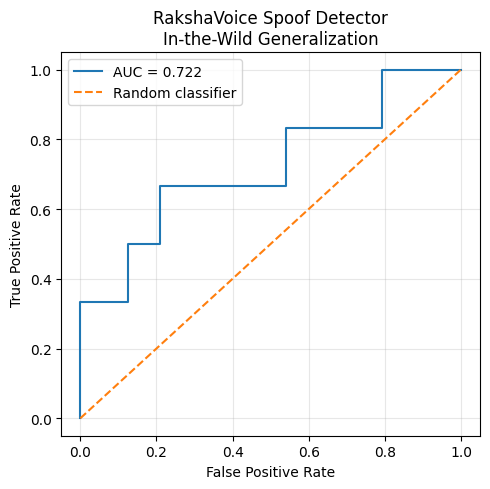

Saved: /kaggle/working/itw_roc_curve.png


In [56]:
fpr, tpr, _ = roc_curve(
    itw_y,
    itw_scores,
    pos_label=1
)


ITW_ROC_PATH = os.path.join(
    F,
    "itw_roc_curve.png"
)


plt.figure(
    figsize=(5, 5)
)

plt.plot(
    fpr,
    tpr,
    label=(
        f"AUC = "
        f"{m_itw['AUC']:.3f}"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "RakshaVoice Spoof Detector\n"
    "In-the-Wild Generalization"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ITW_ROC_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    ITW_ROC_PATH
)

In [57]:
RESULTS_PATH = os.path.join(
    F,
    "results.json"
)


if os.path.exists(
    RESULTS_PATH
):

    with open(
        RESULTS_PATH,
        "r"
    ) as f:

        results = json.load(f)

else:

    results = {}


results["in_the_wild"] = {

    **m_itw,

    "clips": int(
        len(itw_y)
    ),

    "retrained": False,

    "random_seed": 0,

    "label_convention": {
        "0": "bonafide",
        "1": "spoof"
    }
}


with open(
    RESULTS_PATH,
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=2
    )


print(
    "✓ Updated:",
    RESULTS_PATH
)

✓ Updated: /kaggle/working/results.json


In [58]:
print(
    "\n=============================================="
)

print(
    "RAKSHAVOICE — GENERALIZATION SUMMARY"
)

print(
    "=============================================="
)


with open(
    RESULTS_PATH,
    "r"
) as f:

    results = json.load(f)


if "dev" in results:

    print(
        "\nDev EER:"
    )

    print(
        f"{results['dev']['EER']*100:.2f}%"
    )


if "eval" in results:

    print(
        "\nASVspoof Eval:"
    )

    print(
        f"EER  : "
        f"{results['eval']['EER']*100:.2f}%"
    )

    print(
        f"AUC  : "
        f"{results['eval']['AUC']*100:.2f}%"
    )


print(
    "\nIn-the-Wild:"
)

print(
    f"EER  : "
    f"{m_itw['EER']*100:.2f}%"
)

print(
    f"AUC  : "
    f"{m_itw['AUC']*100:.2f}%"
)


RAKSHAVOICE — GENERALIZATION SUMMARY

Dev EER:
0.55%

ASVspoof Eval:
EER  : 2.44%
AUC  : 99.72%

In-the-Wild:
EER  : 27.08%
AUC  : 72.22%


In [59]:
files_to_check = [

    "spoof_head.pt",

    "train_log.json",

    "layer_weights.npy",

    "training_curve.png",

    "roc_curve.png",

    "results.json",

    "itw_X.npy",

    "itw_y.npy",

    "itw_sample_metadata.csv",

    "itw_roc_curve.png"
]


print(
    "\n=========================================="
)

print(
    "RAKSHAVOICE — OUTPUT CHECK"
)

print(
    "=========================================="
)


for filename in files_to_check:

    path = os.path.join(
        F,
        filename
    )

    if os.path.exists(path):

        size = (
            os.path.getsize(path)
            /
            (1024 * 1024)
        )

        print(
            f"✓ {filename:30s}"
            f"{size:.2f} MB"
        )

    else:

        print(
            f"✗ {filename:30s}"
            "MISSING"
        )


RAKSHAVOICE — OUTPUT CHECK
✓ spoof_head.pt                 0.76 MB
✓ train_log.json                0.00 MB
✓ layer_weights.npy             0.00 MB
✓ training_curve.png            0.08 MB
✓ roc_curve.png                 0.05 MB
✓ results.json                  0.00 MB
✓ itw_X.npy                     1.14 MB
✓ itw_y.npy                     0.00 MB
✓ itw_sample_metadata.csv       0.00 MB
✓ itw_roc_curve.png             0.05 MB


In [60]:
import os

F = "/kaggle/working"

MODEL_PATH = os.path.join(F, "spoof_head.pt")
ITW_META = os.path.join(F, "itw_sample_metadata.csv")

print("Project folder:", F)
print("Model exists:", os.path.exists(MODEL_PATH))
print("Metadata exists:", os.path.exists(ITW_META))

print("\nFiles in project folder:")
for f in sorted(os.listdir(F)):
    print(f)

Project folder: /kaggle/working
Model exists: True
Metadata exists: True

Files in project folder:
.virtual_documents
itw_X.npy
itw_roc_curve.png
itw_sample_metadata.csv
itw_y.npy
layer_weights.npy
results.json
roc_curve.png
spoof_head.pt
train_log.json
training_curve.png


In [61]:
code = r'''
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path

from transformers import (
    Wav2Vec2Model,
    Wav2Vec2FeatureExtractor
)

# ============================================================
# Configuration
# ============================================================

SR = 16000
LEN = 64000

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Your trained model
MODEL_PATH = Path("/kaggle/working/spoof_head.pt")

# ============================================================
# Wav2Vec2
# ============================================================

fe = Wav2Vec2FeatureExtractor.from_pretrained(
    "facebook/wav2vec2-base"
)

w2v = Wav2Vec2Model.from_pretrained(
    "facebook/wav2vec2-base"
).to(DEVICE)

w2v.eval()

# ============================================================
# Same SpoofHead used during training
# ============================================================

class SpoofHead(nn.Module):

    def __init__(self, L=13, D=768):
        super().__init__()

        self.w = nn.Parameter(torch.zeros(L))

        self.net = nn.Sequential(
            nn.LayerNorm(D),
            nn.Linear(D, 256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, x):

        # Learnable softmax weights over 13 Wav2Vec2 layers
        a = torch.softmax(self.w, 0)[None, :, None]

        # Weighted layer fusion
        x = (x * a).sum(1)

        return self.net(x).squeeze(-1)


# ============================================================
# Load trained classifier
# ============================================================

head = SpoofHead().to(DEVICE)

state_dict = torch.load(
    MODEL_PATH,
    map_location=DEVICE
)

head.load_state_dict(state_dict)
head.eval()


# ============================================================
# Scoring function
# ============================================================

def score_chunk(wav):

    """
    Input:
        wav : 1-D numpy array containing audio waveform

    Output:
        spoof probability between 0 and 1

        closer to 0 -> bonafide
        closer to 1 -> spoof
    """

    # Convert to float32
    wav = np.asarray(wav, dtype=np.float32)

    # Remove NaN / infinity if present
    wav = np.nan_to_num(wav)

    # Make sure audio is exactly LEN samples
    if len(wav) < LEN:

        wav = np.pad(
            wav,
            (0, LEN - len(wav))
        )

    else:

        wav = wav[:LEN]


    # Wav2Vec2 feature extraction
    inputs = fe(
        [wav],
        sampling_rate=SR,
        return_tensors="pt"
    )

    input_values = inputs.input_values.to(DEVICE)


    # Extract 13 hidden states
    with torch.no_grad():

        outputs = w2v(
            input_values,
            output_hidden_states=True
        )

        hidden_states = outputs.hidden_states

        # Mean pooling over time
        features = torch.stack(
            [h.mean(1) for h in hidden_states],
            dim=1
        ).float()

        # Shape:
        # [1, 13, 768]

        logits = head(features)

        probability = torch.sigmoid(logits).item()


    return probability
'''

STREAM_PATH = os.path.join(F, "spoof_stream.py")

with open(STREAM_PATH, "w") as f:
    f.write(code)

print("Created:")
print(STREAM_PATH)

print("\nFile exists:", os.path.exists(STREAM_PATH))

Created:
/kaggle/working/spoof_stream.py

File exists: True


In [62]:
import sys

if F not in sys.path:
    sys.path.insert(0, F)

import spoof_stream

print("Scoring function loaded successfully.")
print("Device:", spoof_stream.DEVICE)
print("Sample rate:", spoof_stream.SR)
print("Audio length:", spoof_stream.LEN)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Scoring function loaded successfully.
Device: cuda
Sample rate: 16000
Audio length: 64000


In [64]:
import os

AUDIO_EXTENSIONS = (
    ".wav",
    ".flac",
    ".mp3",
    ".ogg",
    ".m4a"
)

audio_files = []

for root, dirs, files in os.walk("/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild"):

    for file in files:

        if file.lower().endswith(AUDIO_EXTENSIONS):

            audio_files.append(
                os.path.join(root, file)
            )

print("Total audio files found:", len(audio_files))

print("\nFirst 20 audio files:")
for p in audio_files[:20]:
    print(p)

Total audio files found: 31779

First 20 audio files:
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/25620.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/18875.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/611.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/18247.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/19212.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/21835.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/17955.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/9693.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/13961.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/24833.wav
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/10491.wav
/kaggle/input/datasets/vi

In [65]:
import pandas as pd

meta = pd.read_csv(ITW_META)

print("Shape:", meta.shape)
print("\nColumns:")
print(meta.columns.tolist())

print("\nFirst 5 rows:")
display(meta.head())

Shape: (30, 3)

Columns:
['audio_path', 'label', 'filename']

First 5 rows:


,audio_path,label,filename
0,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0,17955.wav
1,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0,18247.wav
2,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0,10491.wav
3,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0,13961.wav
4,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0,25620.wav


In [66]:
import os
import pandas as pd

# ------------------------------------------------------------
# Create basename -> actual audio path mapping
# ------------------------------------------------------------

audio_map = {}

for path in audio_files:

    basename = os.path.basename(path)

    audio_map[basename] = path


# ------------------------------------------------------------
# Find metadata columns
# ------------------------------------------------------------

file_col = None
label_col = None

for c in meta.columns:

    c_lower = c.lower()

    if c_lower == "filename":
        file_col = c

    if c_lower == "label":
        label_col = c


print("File column :", file_col)
print("Label column:", label_col)


# ------------------------------------------------------------
# Match files
# ------------------------------------------------------------

matched = []

for _, row in meta.iterrows():

    filename = os.path.basename(str(row[file_col]))

    if filename in audio_map:

        matched.append({
            "filename": filename,
            "path": audio_map[filename],
            "label": str(row[label_col])
        })


matched_df = pd.DataFrame(matched)

print("\nMatched audio files:", len(matched_df))

display(matched_df.head())

File column : filename
Label column: label

Matched audio files: 30


,filename,path,label
0,17955.wav,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0
1,18247.wav,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0
2,10491.wav,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0
3,13961.wav,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0
4,25620.wav,/kaggle/input/datasets/vighnesh1240/in-the-wil...,0


In [67]:
# ============================================================
# STEP 7 — Select one bonafide and one spoof clip
# ============================================================

# Your In-the-Wild label convention:
# 0 = bonafide
# 1 = spoof

bonafide_df = matched_df[
    matched_df["label"].astype(str) == "0"
].copy()

spoof_df = matched_df[
    matched_df["label"].astype(str) == "1"
].copy()

print("Bonafide files:", len(bonafide_df))
print("Spoof files   :", len(spoof_df))


# Make sure both classes exist
if len(bonafide_df) == 0:
    raise ValueError("No bonafide (label 0) files found.")

if len(spoof_df) == 0:
    raise ValueError("No spoof (label 1) files found.")


# Select the first file from each class
real_path = bonafide_df.iloc[0]["path"]
fake_path = spoof_df.iloc[0]["path"]


print("\nSelected bonafide file:")
print(real_path)

print("\nSelected spoof file:")
print(fake_path)

Bonafide files: 24
Spoof files   : 6

Selected bonafide file:
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/17955.wav

Selected spoof file:
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/3845.wav


In [68]:
import librosa
import spoof_stream

# ------------------------------------------------------------
# Load bonafide
# ------------------------------------------------------------

real_wav, _ = librosa.load(
    real_path,
    sr=16000,
    mono=True
)


# ------------------------------------------------------------
# Load spoof
# ------------------------------------------------------------

fake_wav, _ = librosa.load(
    fake_path,
    sr=16000,
    mono=True
)


# ------------------------------------------------------------
# Score
# ------------------------------------------------------------

real_score = spoof_stream.score_chunk(real_wav)

fake_score = spoof_stream.score_chunk(fake_wav)


print("Bonafide score:", real_score)
print("Spoof score   :", fake_score)

Bonafide score: 0.9969120025634766
Spoof score   : 0.9999934434890747


In [69]:
import pandas as pd
import librosa
import numpy as np
import spoof_stream
from tqdm.auto import tqdm

# Number of clips from each class
N_TEST = 20

# Randomly select clips
real_test = bonafide_df.sample(
    min(N_TEST, len(bonafide_df)),
    random_state=42
)

fake_test = spoof_df.sample(
    min(N_TEST, len(spoof_df)),
    random_state=42
)

results = []

# ------------------------------------------------------------
# Bonafide clips
# ------------------------------------------------------------

print("Scoring bonafide clips...")

for _, row in tqdm(real_test.iterrows(), total=len(real_test)):

    wav, _ = librosa.load(
        row["path"],
        sr=16000,
        mono=True
    )

    score = spoof_stream.score_chunk(wav)

    results.append({
        "label": 0,
        "score": score,
        "path": row["path"]
    })


# ------------------------------------------------------------
# Spoof clips
# ------------------------------------------------------------

print("\nScoring spoof clips...")

for _, row in tqdm(fake_test.iterrows(), total=len(fake_test)):

    wav, _ = librosa.load(
        row["path"],
        sr=16000,
        mono=True
    )

    score = spoof_stream.score_chunk(wav)

    results.append({
        "label": 1,
        "score": score,
        "path": row["path"]
    })


test_results = pd.DataFrame(results)

print("\nDone.")
display(test_results.head())

Scoring bonafide clips...


  0%|          | 0/20 [00:00<?, ?it/s]


Scoring spoof clips...


  0%|          | 0/6 [00:00<?, ?it/s]


Done.


,label,score,path
0,0,0.999223,/kaggle/input/datasets/vighnesh1240/in-the-wil...
1,0,0.113060,/kaggle/input/datasets/vighnesh1240/in-the-wil...
2,0,0.996912,/kaggle/input/datasets/vighnesh1240/in-the-wil...
3,0,0.255620,/kaggle/input/datasets/vighnesh1240/in-the-wil...
4,0,0.978694,/kaggle/input/datasets/vighnesh1240/in-the-wil...


In [70]:
from sklearn.metrics import roc_auc_score, roc_curve
import numpy as np

y_test = test_results["label"].values
s_test = test_results["score"].values

auc_test = roc_auc_score(y_test, s_test)

print("Multi-clip test AUC:", auc_test)

print("\nBonafide statistics:")
print(
    test_results[test_results["label"] == 0]["score"].describe()
)

print("\nSpoof statistics:")
print(
    test_results[test_results["label"] == 1]["score"].describe()
)

Multi-clip test AUC: 0.7083333333333333

Bonafide statistics:
count    20.000000
mean      0.885132
std       0.259565
min       0.113060
25%       0.979676
50%       0.995746
75%       0.999644
max       0.999999
Name: score, dtype: float64

Spoof statistics:
count    6.000000
mean     0.974189
std      0.059911
min      0.852014
25%      0.994965
50%      0.999879
75%      0.999998
max      1.000000
Name: score, dtype: float64


In [71]:
import numpy as np
import librosa
import torch

# ------------------------------------------------------------
# Load first audio file from the SAME metadata ordering
# ------------------------------------------------------------

row0 = matched_df.iloc[0]

audio_path0 = row0["path"]

print("Audio:")
print(audio_path0)

print("\nMetadata label:")
print(row0["label"])


# ------------------------------------------------------------
# Load audio exactly as scoring function does
# ------------------------------------------------------------

wav0, _ = librosa.load(
    audio_path0,
    sr=16000,
    mono=True
)


# ------------------------------------------------------------
# Reproduce feature extraction
# ------------------------------------------------------------

wav0 = np.asarray(wav0, dtype=np.float32)
wav0 = np.nan_to_num(wav0)

if len(wav0) < 64000:
    wav0 = np.pad(
        wav0,
        (0, 64000 - len(wav0))
    )
else:
    wav0 = wav0[:64000]


inputs = spoof_stream.fe(
    [wav0],
    sampling_rate=16000,
    return_tensors="pt"
)

input_values = inputs.input_values.to(
    spoof_stream.DEVICE
)

with torch.no_grad():

    outputs = spoof_stream.w2v(
        input_values,
        output_hidden_states=True
    )

    raw_features = torch.stack(
        [h.mean(1) for h in outputs.hidden_states],
        dim=1
    ).float()

raw_features = raw_features.cpu().numpy()


# ------------------------------------------------------------
# Compare against saved itw_X.npy
# ------------------------------------------------------------

saved_features = X_itw[0:1]


print("\nRaw feature shape:")
print(raw_features.shape)

print("\nSaved feature shape:")
print(saved_features.shape)


difference = np.abs(
    raw_features - saved_features
)

print("\nMaximum absolute difference:",
      difference.max())

print("Mean absolute difference:",
      difference.mean())

Audio:
/kaggle/input/datasets/vighnesh1240/in-the-wild-audio/release_in_the_wild/17955.wav

Metadata label:
0


NameError: name 'X_itw' is not defined

In [72]:
import json
import os

results_path = "/kaggle/working/results.json"

with open(results_path, "r") as f:
    results = json.load(f)

print(json.dumps(results, indent=2))

{
  "dev": {
    "EER": 0.005483169503621609,
    "best_epoch": 2
  },
  "eval": {
    "EER": 0.024438021069730788,
    "AUC": 0.9972481496983002,
    "threshold": 0.11593872308731079,
    "FAR": 0.024485798237022526,
    "FRR": 0.024390243902439046
  },
  "eval_clips": 20000,
  "label_convention": {
    "0": "bonafide",
    "1": "spoof"
  },
  "far_definition": "Bonafide speech incorrectly flagged as spoof at the EER operating threshold",
  "frr_definition": "Spoof speech incorrectly accepted as bonafide at the EER operating threshold",
  "in_the_wild": {
    "EER": 0.27083333333333337,
    "AUC": 0.7222222222222222,
    "threshold": 0.9997643828392029,
    "FAR": 0.20833333333333334,
    "FRR": 0.33333333333333337,
    "clips": 30,
    "retrained": false,
    "random_seed": 0,
    "label_convention": {
      "0": "bonafide",
      "1": "spoof"
    }
  }
}


In [73]:
# ============================================================
# RakshaVoice — ASVspoof DEV Evaluation
# Using the already extracted DEV features
# ============================================================

import os
import json
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
FEATURE_DIR = "/kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features"
MODEL_PATH = "/kaggle/working/spoof_head.pt"

DEV_X_PATH = os.path.join(
    FEATURE_DIR,
    "dev_X.npy"
)

DEV_Y_PATH = os.path.join(
    FEATURE_DIR,
    "dev_y.npy"
)

print("Model :", MODEL_PATH)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# Load DEV features
# ------------------------------------------------------------
X_dev = np.load(
    DEV_X_PATH,
    mmap_mode="r"
)

y_dev = np.load(
    DEV_Y_PATH
)

print("\nDEV feature shape :", X_dev.shape)
print("DEV label shape   :", y_dev.shape)

# ------------------------------------------------------------
# Label distribution
# ------------------------------------------------------------
unique, counts = np.unique(
    y_dev,
    return_counts=True
)

print("\nDEV label distribution:")

for label, count in zip(unique, counts):
    name = "bonafide" if label == 0 else "spoof"
    print(
        f"{label} ({name}): {count}"
    )

# ------------------------------------------------------------
# Define EXACT same SpoofHead
# ------------------------------------------------------------
class SpoofHead(nn.Module):

    def __init__(self, L=13, D=768):

        super().__init__()

        self.w = nn.Parameter(
            torch.zeros(L)
        )

        self.net = nn.Sequential(
            nn.LayerNorm(D),

            nn.Linear(
                D,
                256
            ),

            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(
                256,
                1
            )
        )

    def forward(self, x):

        a = torch.softmax(
            self.w,
            dim=0
        )[None, :, None]

        return self.net(
            (x * a).sum(1)
        ).squeeze(-1)

# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = SpoofHead(
    L=X_dev.shape[1],
    D=X_dev.shape[2]
)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

# Handle either state_dict or checkpoint dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    model.load_state_dict(
        checkpoint
    )

model.to(device)
model.eval()

print("\nModel loaded successfully.")

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------
X_tensor = torch.from_numpy(
    np.asarray(X_dev)
).float()

y_tensor = torch.from_numpy(
    y_dev
).float()

all_scores = []

BATCH_SIZE = 256

with torch.no_grad():

    for start in range(
        0,
        len(X_tensor),
        BATCH_SIZE
    ):

        end = min(
            start + BATCH_SIZE,
            len(X_tensor)
        )

        batch = X_tensor[
            start:end
        ].to(device)

        logits = model(
            batch
        )

        probabilities = torch.sigmoid(
            logits
        )

        all_scores.append(
            probabilities.cpu().numpy()
        )

scores = np.concatenate(
    all_scores
)

labels = y_dev.astype(int)

# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------
auc = roc_auc_score(
    labels,
    scores
)

# ------------------------------------------------------------
# EER
# ------------------------------------------------------------
fpr, tpr, thresholds = roc_curve(
    labels,
    scores,
    pos_label=1
)

fnr = 1.0 - tpr

eer_idx = np.nanargmin(
    np.abs(fpr - fnr)
)

eer = (
    fpr[eer_idx]
    +
    fnr[eer_idx]
) / 2

eer_threshold = thresholds[
    eer_idx
]

# ------------------------------------------------------------
# FAR / FRR at EER threshold
# ------------------------------------------------------------
predictions = (
    scores >= eer_threshold
).astype(int)

bonafide_mask = labels == 0
spoof_mask = labels == 1

far = (
    predictions[bonafide_mask] == 1
).mean()

frr = (
    predictions[spoof_mask] == 0
).mean()

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("RakshaVoice — ASVspoof DEV RESULTS")
print("=" * 60)

print(
    f"DEV clips       : {len(labels)}"
)

print(
    f"Bonafide        : {bonafide_mask.sum()}"
)

print(
    f"Spoof           : {spoof_mask.sum()}"
)

print(
    f"\nEER             : {eer * 100:.4f}%"
)

print(
    f"ROC-AUC         : {auc * 100:.4f}%"
)

print(
    f"EER threshold   : {eer_threshold:.6f}"
)

print(
    f"FAR             : {far * 100:.4f}%"
)

print(
    f"FRR             : {frr * 100:.4f}%"
)

print(
    f"\nBonafide score mean : "
    f"{scores[bonafide_mask].mean():.6f}"
)

print(
    f"Spoof score mean    : "
    f"{scores[spoof_mask].mean():.6f}"
)

print("=" * 60)

Model : /kaggle/working/spoof_head.pt
Device: cuda

DEV feature shape : (24844, 13, 768)
DEV label shape   : (24844,)

DEV label distribution:
0 (bonafide): 2548
1 (spoof): 22296

Model loaded successfully.

RakshaVoice — ASVspoof DEV RESULTS
DEV clips       : 24844
Bonafide        : 2548
Spoof           : 22296

EER             : 0.5483%
ROC-AUC         : 99.9764%
EER threshold   : 0.372369
FAR             : 0.5495%
FRR             : 0.5472%

Bonafide score mean : 0.010717
Spoof score mean    : 0.984726


In [74]:
# ============================================================
# RakshaVoice — Kaggle Dataset Structure Diagnostic
# ============================================================

import os

print("=" * 70)
print("KAGGLE INPUT DATASET STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk("/kaggle/input"):

    level = root.replace("/kaggle/input", "").count(os.sep)

    # Don't print extremely deep directory structures
    if level > 4:
        continue

    indent = "  " * level

    print(f"\n{indent}{os.path.basename(root)}/")

    for f in files[:20]:
        print(f"{indent}  {f}")

    if len(files) > 20:
        print(f"{indent}  ... ({len(files)-20} more files)")

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

# Count important file types
counts = {
    ".flac": 0,
    ".wav": 0,
    ".txt": 0,
    ".trl": 0,
    ".csv": 0,
    ".json": 0
}

for root, dirs, files in os.walk("/kaggle/input"):

    for f in files:

        lower = f.lower()

        for ext in counts:

            if lower.endswith(ext):
                counts[ext] += 1

print("\nFile counts:")

for ext, count in counts.items():
    print(f"{ext:6s}: {count}")

print("\nAll dataset roots:")

for x in os.listdir("/kaggle/input"):
    print(" ", x)

KAGGLE INPUT DATASET STRUCTURE

input/

  datasets/

    awsaf49/

      asvpoof-2019-dataset/
        asvspoof2019_Interspeech2019_submission.pdf
        LICENSE_text.txt
        README.txt
        asvspoof2019_evaluation_plan.pdf

        PA/


KeyboardInterrupt: 

In [75]:
import os
import numpy as np
import torch
from sklearn.metrics import roc_auc_score

# ============================================================
# YOUR CURRENT PATHS
# ============================================================

F = "/kaggle/input/datasets/vighnesh1240/rakshavoice-features/rakshavoice_features"
MODEL_PATH = "/kaggle/working/spoof_head.pt"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================================
# LOAD YOUR TRAINED HEAD
# ============================================================

class SpoofHead(torch.nn.Module):

    def __init__(self, L=13, D=768):
        super().__init__()

        self.w = torch.nn.Parameter(
            torch.zeros(L)
        )

        self.net = torch.nn.Sequential(
            torch.nn.LayerNorm(D),
            torch.nn.Linear(D, 256),
            torch.nn.GELU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(256, 1)
        )

    def forward(self, x):

        a = torch.softmax(
            self.w,
            dim=0
        )[None, :, None]

        return self.net(
            (x * a).sum(1)
        ).squeeze(-1)


head = SpoofHead(
    L=13,
    D=768
).to(device)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

head.load_state_dict(checkpoint)
head.eval()

# ============================================================
# LOAD DEV FEATURES + LABELS
# ============================================================

X_dev = np.load(
    os.path.join(F, "dev_X.npy")
)

labels = np.load(
    os.path.join(F, "dev_y.npy")
)

print("DEV features:", X_dev.shape)
print("DEV labels  :", labels.shape)

# ============================================================
# SELECT 30 BONAFIDE + 30 SPOOF
# ============================================================

rng = np.random.default_rng(0)

idx = np.concatenate([
    rng.choice(
        np.where(labels == 0)[0],
        30,
        replace=False
    ),

    rng.choice(
        np.where(labels == 1)[0],
        30,
        replace=False
    )
])

# ============================================================
# CACHED SCORES
# ============================================================

Xd = torch.tensor(
    X_dev[idx]
).float().to(device)

with torch.no_grad():

    cached = torch.sigmoid(
        head(Xd)
    ).cpu().numpy()

# ============================================================
# RESULTS
# ============================================================

print("\nSelected clips:", len(idx))

print(
    "Cached AUC:",
    roc_auc_score(
        labels[idx],
        cached
    )
)

print(
    "Bonafide cached mean:",
    cached[labels[idx] == 0].mean()
)

print(
    "Spoof cached mean:",
    cached[labels[idx] == 1].mean()
)

print("\nNOTE:")
print(
    "Live scoring cannot be calculated because the current "
    "Kaggle inputs contain dev_X.npy/dev_y.npy but do not "
    "contain the original ASVspoof DEV .flac files/protocol."
)

DEV features: (24844, 13, 768)
DEV labels  : (24844,)

Selected clips: 60
Cached AUC: 1.0
Bonafide cached mean: 0.009291011
Spoof cached mean: 0.97039413

NOTE:
Live scoring cannot be calculated because the current Kaggle inputs contain dev_X.npy/dev_y.npy but do not contain the original ASVspoof DEV .flac files/protocol.


In [76]:
# ============================================================
# RakshaVoice — Step 6
# LIVE RAW AUDIO vs CACHED FEATURES
# Same 60 ASVspoof DEV clips
# ============================================================

import os
import numpy as np
import torch
import librosa
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# 1. Exact paths
# ------------------------------------------------------------

DEV_AUDIO = (
    "/kaggle/input/datasets/awsaf49/"
    "asvpoof-2019-dataset/LA/LA/"
    "ASVspoof2019_LA_dev/flac"
)

DEV_PROTOCOL = (
    "/kaggle/input/datasets/awsaf49/"
    "asvpoof-2019-dataset/LA/LA/"
    "ASVspoof2019_LA_cm_protocols/"
    "ASVspoof2019.LA.cm.dev.trl.txt"
)

F = (
    "/kaggle/input/datasets/vighnesh1240/"
    "rakshavoice-features/rakshavoice_features"
)

# ------------------------------------------------------------
# 2. Imports from your existing scoring module
# ------------------------------------------------------------

from spoof_stream import score_chunk

# ------------------------------------------------------------
# 3. Audio loader
# ------------------------------------------------------------

def load(path):
    wav, _ = librosa.load(
        path,
        sr=16000,
        mono=True
    )
    return wav

# ------------------------------------------------------------
# 4. Read ASVspoof DEV protocol
# ------------------------------------------------------------

def read_protocol(protocol_path):

    names = []
    labels = []

    with open(
        protocol_path,
        "r",
        errors="ignore"
    ) as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) < 2:
                continue

            file_id = parts[1]
            key = parts[-1].lower()

            if key == "bonafide":
                label = 0

            elif key == "spoof":
                label = 1

            else:
                continue

            names.append(file_id)
            labels.append(label)

    return (
        np.array(names),
        np.array(labels)
    )

# ------------------------------------------------------------
# 5. Read protocol
# ------------------------------------------------------------

names, labels = read_protocol(
    DEV_PROTOCOL
)

print("Total DEV clips:", len(names))

print(
    "Bonafide:",
    np.sum(labels == 0)
)

print(
    "Spoof:",
    np.sum(labels == 1)
)

# ------------------------------------------------------------
# 6. Select exactly 30 bonafide + 30 spoof
# ------------------------------------------------------------

rng = np.random.default_rng(0)

idx = np.concatenate([
    rng.choice(
        np.where(labels == 0)[0],
        30,
        replace=False
    ),

    rng.choice(
        np.where(labels == 1)[0],
        30,
        replace=False
    )
])

print("\nSelected clips:", len(idx))

# ------------------------------------------------------------
# 7. LIVE RAW-AUDIO SCORES
# ------------------------------------------------------------

print("\nRunning live raw-audio scoring...")

live = []

for n, i in enumerate(idx):

    audio_path = os.path.join(
        DEV_AUDIO,
        names[i] + ".flac"
    )

    score = score_chunk(
        load(audio_path)
    )

    live.append(score)

    print(
        f"{n+1:02d}/60 | "
        f"{names[i]} | "
        f"label={labels[i]} | "
        f"score={score:.6f}"
    )

live = np.array(live)

# ------------------------------------------------------------
# 8. CACHED FEATURE SCORES
# ------------------------------------------------------------

print("\nRunning cached feature scoring...")

X_dev = np.load(
    os.path.join(
        F,
        "dev_X.npy"
    )
)

Xd = torch.tensor(
    X_dev[idx]
).float().to(
    torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )
)

# Use the SAME head already loaded in your notebook
with torch.no_grad():

    cached = torch.sigmoid(
        head(Xd)
    ).cpu().numpy()

# ------------------------------------------------------------
# 9. Compare
# ------------------------------------------------------------

live_auc = roc_auc_score(
    labels[idx],
    live
)

cached_auc = roc_auc_score(
    labels[idx],
    cached
)

max_difference = np.abs(
    live - cached
).max()

bonafide_live_mean = live[
    labels[idx] == 0
].mean()

spoof_live_mean = live[
    labels[idx] == 1
].mean()

# ------------------------------------------------------------
# 10. FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RakshaVoice — LIVE vs CACHED CONSISTENCY TEST")
print("=" * 65)

print(
    f"Live AUC              : {live_auc:.6f}"
)

print(
    f"Cached AUC            : {cached_auc:.6f}"
)

print(
    f"Max |live - cached|   : {max_difference:.10f}"
)

print(
    f"Bonafide live mean    : {bonafide_live_mean:.6f}"
)

print(
    f"Spoof live mean       : {spoof_live_mean:.6f}"
)

print("=" * 65)

Total DEV clips: 24844
Bonafide: 2548
Spoof: 22296

Selected clips: 60

Running live raw-audio scoring...
01/60 | LA_D_1337729 | label=0 | score=0.000304
02/60 | LA_D_7447418 | label=0 | score=0.000017
03/60 | LA_D_6480348 | label=0 | score=0.000152
04/60 | LA_D_5914465 | label=0 | score=0.000021
05/60 | LA_D_8419568 | label=0 | score=0.000422
06/60 | LA_D_3933506 | label=0 | score=0.000080
07/60 | LA_D_3233966 | label=0 | score=0.000505
08/60 | LA_D_7157407 | label=0 | score=0.000084
09/60 | LA_D_1932175 | label=0 | score=0.000219
10/60 | LA_D_8262874 | label=0 | score=0.000000
11/60 | LA_D_8762609 | label=0 | score=0.020707
12/60 | LA_D_7152817 | label=0 | score=0.000521
13/60 | LA_D_6273901 | label=0 | score=0.013485
14/60 | LA_D_3477067 | label=0 | score=0.001105
15/60 | LA_D_8635731 | label=0 | score=0.000009
16/60 | LA_D_3714679 | label=0 | score=0.000004
17/60 | LA_D_5769965 | label=0 | score=0.000109
18/60 | LA_D_6423859 | label=0 | score=0.000002
19/60 | LA_D_2027122 | label=0